In [2]:
# import libraries
import pandas as pd
import random as rnd
import numpy as np
import seaborn as sns
import logging
import matplotlib.pyplot as plt
from textblob import TextBlob
import string
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

# nltk.download('vader_lexicon')

rng = np.random.default_rng(seed=1234) # setting up pseudo-random numbers

pd.set_option('display.max_columns',50) # setting up the dataframe display columns
pd.set_option('display.max_colwidth', 100) # setting up column width 100

**About dataset**:

The "labeledTrainData" is a labeled tab-delimited dataset and has a header row followed by 25,000 rows containing an id, sentiment, and text for each review. The sentiment of reviews is binary, meaning score 0 is negative and score 1 is positive.

https://www.kaggle.com/competitions/word2vec-nlp-tutorial/data?select=labeledTrainData.tsv.zip

**id** - Unique ID of each review

**sentiment** - Sentiment of the review; 1 for positive reviews and 0 for negative reviews

**review** - Text of the review

### Loading the dataset in dataframe

In [3]:
file_IMDB_Movie_Reviews= 'labeledTrainData.tsv' # file is saved in current directory.

# Catch any exception reading file
try:
    df_review = pd.read_csv(f"{file_IMDB_Movie_Reviews}", sep="\t")
except FileNotFoundError as e: # if file is not not found. 
    logging.error(f"{file_IMDB_Movie_Reviews} is not found, please check the file path or name.\n{e}")

In [4]:
df_review.head()

,id,sentiment,review
0,5814_8,1,"With all this stuff going down at the moment with MJ i've started listening to his music, watchi..."
1,2381_9,1,"\The Classic War of the Worlds\"" by Timothy Hines is a very entertaining film that obviously goe..."
2,7759_3,0,The film starts with a manager (Nicholas Bell) giving welcome investors (Robert Carradine) to Pr...
3,3630_4,0,"It must be assumed that those who praised this film (\the greatest filmed opera ever,\"" didn't I..."
4,9495_8,1,"Superbly trashy and wondrously unpretentious 80's exploitation, hooray! The pre-credits opening ..."


In [5]:
# Count positive reviews
positive_review = df_review[df_review["sentiment"]==1]["sentiment"].count()
# Count negative reviews
negative_review = df_review[df_review["sentiment"]==0]["sentiment"].count()

print("Positive reviews (total counts) = ",positive_review)
print("Negative reviews (total counts) = ",negative_review)

Positive reviews (total counts) =  12500
Negative reviews (total counts) =  12500


We are performing some data cleaning like removing html tag.

### Preparing text data for model

- Converting all text to lowercase letters
- Removing punctuation and special characters from the text
- Removing stop words
- Apply NLTK’s PorterStemmer

In [6]:
# Load library
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.porter import PorterStemmer

df = df_review.copy()

In [7]:
# load set of stopwords for faster lookup
stop_words = set(stopwords.words("english"))

# creating stemmer
porter = PorterStemmer()

In [8]:
# NOTE: this section is just for testing wheather my code is working before running big dataset
text = "The science of today is the technology of tomorrow Tomorrow is today"
word_token = word_tokenize(text)
word_stop = [word for word in word_token if word not in stop_words]
wrod_stem = [porter.stem(word) for word in word_stop]
wrod_stem

['the', 'scienc', 'today', 'technolog', 'tomorrow', 'tomorrow', 'today']

In [9]:
def clean_text(text: str) -> str:
    # Make lowercase and remove punctuation
    text = text.lower()
    text = text.replace('<br />', ' ') # Remove html tag
    text = text.translate(str.maketrans('', '', string.punctuation))

    word_token = word_tokenize(text)
    word_stop = [ word for word in word_token if word not in stop_words]
    wrod_stem = [porter.stem(word) for word in word_stop]

    # CountVectorizer needs a string, not a list.
    return " ".join(wrod_stem) #  return the "sentence" of stems.

# applying function to each element of review
df['review_stem'] = df['review'].apply(clean_text)

In [10]:
df.head()

,id,sentiment,review,review_stem
0,5814_8,1,"With all this stuff going down at the moment with MJ i've started listening to his music, watchi...",stuff go moment mj ive start listen music watch odd documentari watch wiz watch moonwalk mayb wa...
1,2381_9,1,"\The Classic War of the Worlds\"" by Timothy Hines is a very entertaining film that obviously goe...",classic war world timothi hine entertain film obvious goe great effort length faith recreat h g ...
2,7759_3,0,The film starts with a manager (Nicholas Bell) giving welcome investors (Robert Carradine) to Pr...,film start manag nichola bell give welcom investor robert carradin primal park secret project mu...
3,3630_4,0,"It must be assumed that those who praised this film (\the greatest filmed opera ever,\"" didn't I...",must assum prais film greatest film opera ever didnt read somewher either dont care opera dont c...
4,9495_8,1,"Superbly trashy and wondrously unpretentious 80's exploitation, hooray! The pre-credits opening ...",superbl trashi wondrous unpretenti 80 exploit hooray precredit open sequenc somewhat give fals i...


### Encoding Review's text as Bag of Words

In [11]:
# load library
from sklearn.feature_extraction.text import CountVectorizer

In [12]:
cv = CountVectorizer()
bag_of_words = cv.fit_transform(df['review_stem']) #.toarray()

print(f"Bag of Words Shape: {bag_of_words.shape}")

Bag of Words Shape: (25000, 82874)


In [13]:
bag_of_words.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(25000, 82874))

### Weighting Word Importance using TF-IDF
- term frequency-inverse document frequency (tf-idf) matrix

In [14]:
# load library
from sklearn.feature_extraction.text import TfidfVectorizer

In [15]:
# import libraries
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import set_config

# Switching to text
set_config(display=False)

### Splitting dataset into Train and Test

In [16]:
# Split the data into train and test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['review_stem'], 
    df['sentiment'], 
    test_size=0.2, 
    random_state=42,
    stratify=df['sentiment'] # split with stratification and default settings already include shuffle=True
)

**TfidfVectorizer()** creates both Term Frequency (TF) and Inverse Document Frequency (IDF).

TfidfVectorizer combines two steps:

CountVectorizer -> computes term frequency (TF)

TfidfTransformer -> computes inverse document frequency (IDF) and multiplies it with TF

### Creating TF-IDF feature matrix

In [17]:
# Create the tf-idf feature matrix
tfidf = TfidfVectorizer()

# Fitting the data- Learning vocabulary and IDF from training data
tfidf.fit(X_train_raw)

# Applying learned parameters to training data
X_train = tfidf.transform(X_train_raw)

In [18]:
print(f" Training Data: Term frequency-inverse document frequency (tf-idf) Matrix Shape: {X_train.shape}")

 Training Data: Term frequency-inverse document frequency (tf-idf) Matrix Shape: (20000, 72792)


In [19]:
# TF-IDF features matix, training data
X_train.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(20000, 72792))

In [20]:
# Transforming the Test Set, and do not Apply Fit 
X_test = tfidf.transform(X_test_raw)

In [21]:
print(f"Test Data: Term frequency-inverse document frequency (tf-idf) Matrix Shape: {X_test.shape}")

Test Data: Term frequency-inverse document frequency (tf-idf) Matrix Shape: (5000, 72792)


The test data is only transformed using the TF-IDF parameters learned from the training set.

We fit and transform on train data, but only transform on test data to avoid the data leakage problem.

If we fit on the test set, the vectorizer might learn words or frequency patterns that only exist in the test data. In a real-world scenario, we would not know the future data (test set) ahead of time. By using only the training dictionary to transform the test set, we ensure the model is evaluated on how it handles unseen vocabulary.

**Key rule:** Any step that learns statistics from data must be fit on the training set only.

## Logistic Regression- Training

In [22]:
# Training Logistic Regression
logit = LogisticRegression()
logit.fit(X_train, y_train)

LogisticRegression()

In [22]:
# Prediction and Accuracy
y_pred = logit.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Logistic Regression Accuracy: {accuracy:.4f}")

Logistic Regression Accuracy: 0.8872


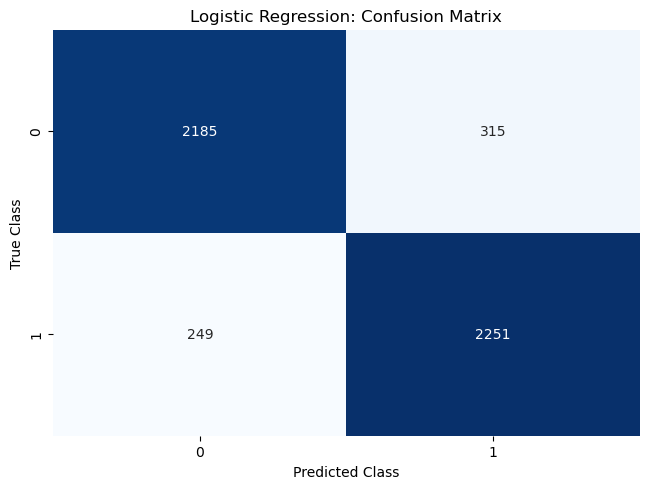

In [23]:
# confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# create confusion matrix
conf_df = pd.DataFrame(conf_matrix, index = logit.classes_, columns = logit.classes_)

# Decimal places and no scientific notation
pd.options.display.float_format = '{:.4f}'.format

# create heatmap
sns.heatmap(conf_df, annot = True, fmt = 'd', cbar = None, cmap = "Blues")
plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.show()

In [24]:
# Precision, Recall, F1-score
class_report = classification_report(y_test, y_pred)
print("\nLogistic Regression- Classification Report:\n", class_report)


Logistic Regression- Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.87      0.89      2500
           1       0.88      0.90      0.89      2500

    accuracy                           0.89      5000
   macro avg       0.89      0.89      0.89      5000
weighted avg       0.89      0.89      0.89      5000



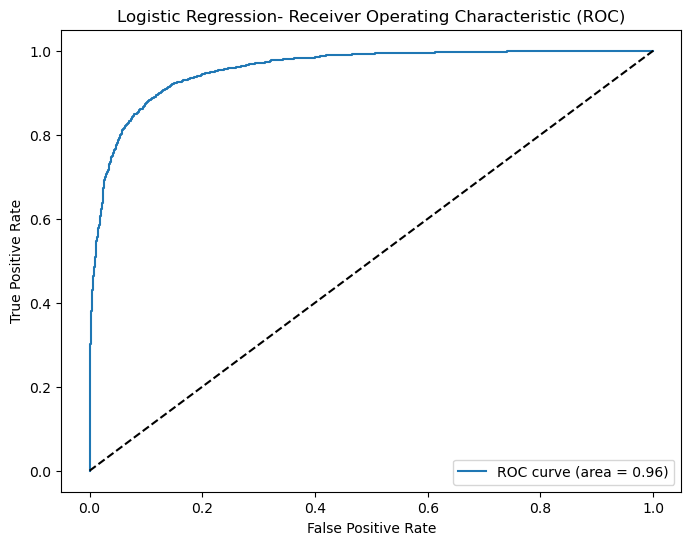

In [25]:
# ROC Curve
y_prob = logit.predict_proba(X_test)[:,1] # Get probability for the positive class

# create true and false positive rates 
false_positive_rate, true_positive_rate, threshold = roc_curve(y_test, y_prob )

roc_auc = auc(false_positive_rate, true_positive_rate)

plt.figure(figsize=(8, 6))
plt.plot(false_positive_rate, true_positive_rate, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--') # Diagonal line representing random guessing
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression- Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Logistic Regression** model performed with an 88.72% accuracy, successfully identifying sentiment in nearly 9 out of 10 reviews. 

It shows a 0.90 recall, proving it is excellent at capturing the vast majority of actual positive feedback. With identical F1-scores of 0.89 for both classes, the model is perfectly balanced and shows no bias toward either sentiment.

## Random Forest- Training

In [26]:
# import modules
from sklearn.ensemble import RandomForestClassifier

In [27]:
# Train a Random Forest using the training data
# n_estimators=100 means we are using 100 decision trees
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [28]:
# Prediction and Accuracy
y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {accuracy_rf:.4f}")

Random Forest Accuracy: 0.8454


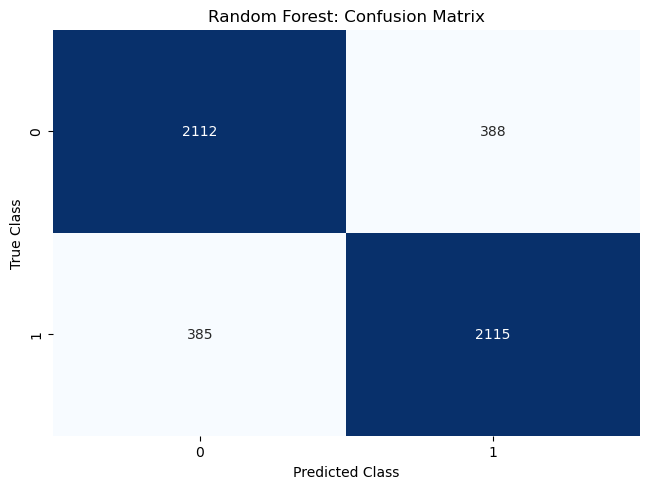

In [29]:
# confusion matrix
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf)

# create confusion matrix
conf_rf_df = pd.DataFrame(conf_matrix_rf, index = rf_model.classes_, columns = rf_model.classes_)

# Decimal places and no scientific notation
pd.options.display.float_format = '{:.4f}'.format

# create heatmap
sns.heatmap(conf_rf_df, annot = True, fmt = 'd', cbar = None, cmap = "Blues")
plt.title("Random Forest: Confusion Matrix")
plt.tight_layout()
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.show()

In [30]:
# Precision, Recall, F1-score
class_report_rf = classification_report(y_test, y_pred_rf)
print("\nRandom Forest- Classification Report:\n", class_report_rf)


Random Forest- Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.84      0.85      2500
           1       0.84      0.85      0.85      2500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000



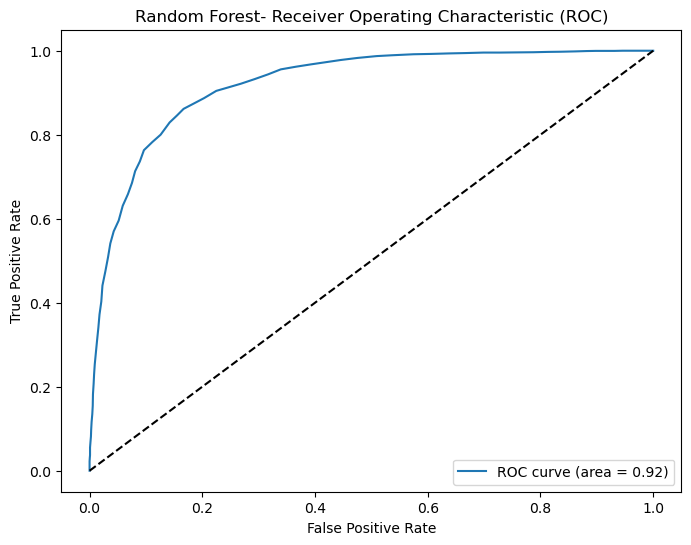

In [31]:
# ROC Curve
y_prob_rf = rf_model.predict_proba(X_test)[:,1] # Get probability for the positive class

# create true and false positive rates 
false_positive_rate_rf, true_positive_rate_rf, threshold_rf = roc_curve(y_test, y_prob_rf )

roc_auc_rf = auc(false_positive_rate_rf, true_positive_rate_rf)

plt.figure(figsize=(8, 6))
plt.plot(false_positive_rate_rf, true_positive_rate_rf, label=f'ROC curve (area = {roc_auc_rf:.2f})')
plt.plot([0, 1], [0, 1], 'k--') # Diagonal line representing random guessing
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest- Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Random Forest** model got 84.54% accuracy, correctly predicting sentiment for the majority of reviews. 

It shows high consistency across both classes, with precision and recall scores ranging between 0.84 and 0.85. the 0.85 precision ensures few false alarms, while the 0.85 recall for Positive (1) reviews confirms it successfully captures most favorable sentiments. 
The uniform F1-score of 0.85 demonstrates a stable, well-balanced classifier with no significant performance bias.